# 02 Modeling: เทียบ 8 โมเดล + อธิบายผล

ต่อจาก notebook 01 (ต้องมีไฟล์ `dataset_europe_v1.parquet` ใน Drive ก่อน)

| ส่วน | ทำอะไร | บทเรียน |
| --- | --- | --- |
| A | EDA + feature engineering (lag ตามเส้นทางบิน) | L05, L11 |
| B | Feature selection | L10 |
| C | แบ่งข้อมูลตามเที่ยวบิน + เทรน 8 โมเดล + tune | L02–L07, L12 |
| D | ประเมินผล | L04, L06 |
| E | อธิบายโมเดล: permutation, SHAP, EBM | L10 |
| F | PCA + KMeans จับกลุ่มอากาศของตัวร้าย | L08, L09 |
| G | เอาโมเดลยุโรปไปทายฟ้าไทย/อาเซียน | — |

In [1]:
!pip -q install xgboost shap interpret imbalanced-learn pyarrow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = pathlib.Path("/content/drive/MyDrive/Environmental-ML-Project")
except ImportError:
    BASE = pathlib.Path("..")
DATA_DIR, FIG_DIR = BASE / "data", BASE / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
df = pd.read_parquet(DATA_DIR / "dataset_europe_v1.parquet")
print(df.shape)
print(df["villain"].value_counts(normalize=True).rename("share"))

Mounted at /content/drive
(263045, 27)
villain
0    0.978734
1    0.021266
Name: share, dtype: float64


## A. EDA + feature engineering
- ช่วงบินที่ไม่เกิด contrail เลยมีมาก ข้อมูลจึงไม่สมดุล (ตัวร้ายมีแค่ไม่กี่ %)
- เพิ่ม lag ตามเส้นทางบิน (L11): ความชื้นเมื่อ 5 นาทีก่อน และค่าเฉลี่ย 10 นาทีที่ผ่านมา เพราะ contrail ขึ้นกับว่าเครื่องเพิ่งบินเข้าโซนชื้นหรืออยู่ในนั้นมานานแล้ว
- ไม่ใช้ละติจูด/ลองจิจูดเป็น feature เพื่อให้โมเดลเรียนจากฟิสิกส์ของอากาศ ไม่ใช่จำตำแหน่ง และเอาไปใช้กับฟ้าไทยได้

In [3]:
def add_features(d):
    d = d.sort_values(["flight_id", "time"]).copy()
    g = d.groupby("flight_id")
    d["rhi_lag5"] = g["rhi"].shift(5)
    d["rhi_roll10"] = g["rhi"].transform(lambda s: s.rolling(10, min_periods=1).mean())
    d["temp_lag5"] = g["air_temperature"].shift(5)
    d["wind_speed"] = np.hypot(d["u_wind"], d["v_wind"])
    for c in ["rhi_lag5", "temp_lag5"]:
        d[c] = d[c].fillna(d["rhi" if c.startswith("rhi") else "air_temperature"])
    return d.reset_index(drop=True)

df = add_features(df)

# เรียง rhi ไว้ก่อน rh เพื่อให้ขั้น correlation เก็บ rhi (ตัวแปรหลักทางฟิสิกส์) ไว้
NUM_FEATURES = ["altitude_ft", "air_temperature", "rhi", "specific_humidity", "rh", "rhi_lag5", "rhi_roll10",
                "temp_lag5", "u_wind", "v_wind", "wind_speed", "air_pressure", "fuel_flow", "true_airspeed",
                "thrust_setting", "engine_efficiency", "hour_sin", "hour_cos", "is_night"]
NUM_FEATURES = [c for c in NUM_FEATURES if c in df]
CAT_FEATURES = ["aircraft_type"]
X_all = pd.get_dummies(df[NUM_FEATURES + CAT_FEATURES], columns=CAT_FEATURES, dtype=float)
X_all = X_all.fillna(X_all.median())
y_all = df["villain"].astype(int).values
groups = df["flight_id"].values
print(X_all.shape)

(263045, 27)


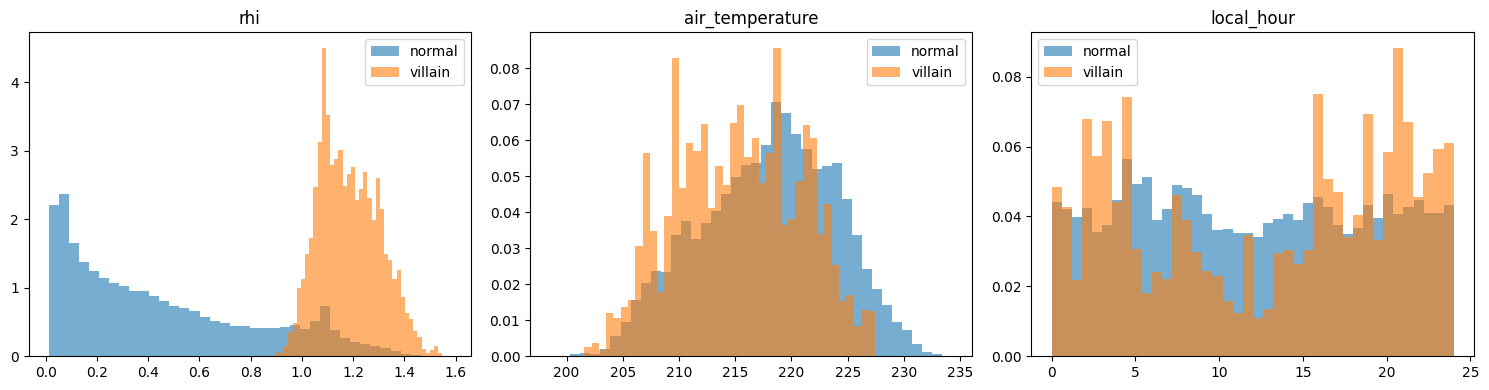

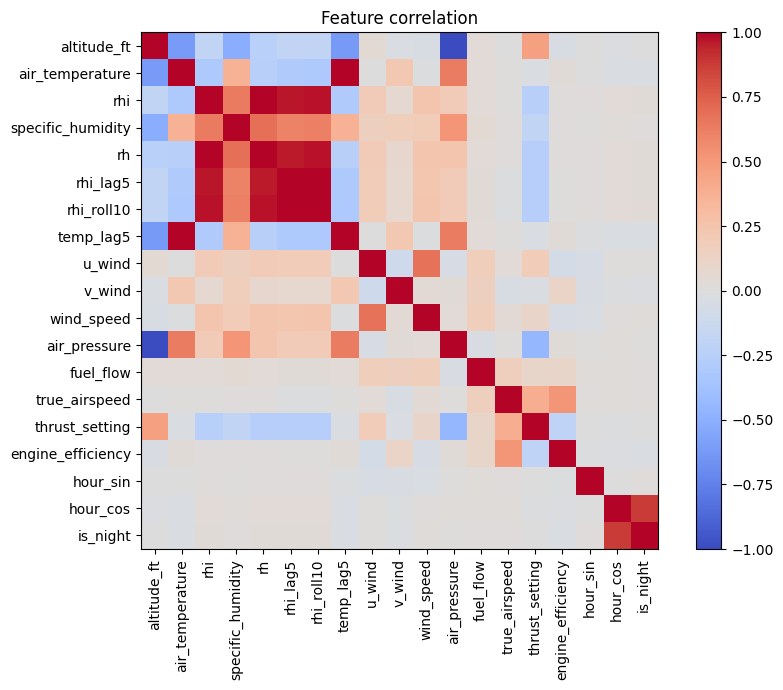

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["rhi", "air_temperature", "local_hour"]):
    for lab, name in [(0, "normal"), (1, "villain")]:
        a.hist(df.loc[df["villain"] == lab, col], bins=40, alpha=0.6, density=True, label=name)
    a.set_title(col); a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_hist.png", dpi=150); plt.show()

corr = X_all[NUM_FEATURES].corr()
plt.figure(figsize=(9, 7)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
plt.title("Feature correlation"); plt.tight_layout(); plt.savefig(FIG_DIR / "corr.png", dpi=150); plt.show()

## B. Feature selection (L10)
ใช้ 4 วิธีจากบทเรียน แล้วเก็บ feature ที่ผ่านเกณฑ์ ไปใช้กับโมเดลที่ไวต่อ feature เยอะ (Logistic, SVM, KNN, NB)
1. Variance threshold: ตัด feature ที่แทบไม่เปลี่ยนค่า
2. Correlation: ถ้าสองตัวสัมพันธ์กันเกิน 0.95 เก็บไว้ตัวเดียว
3. Mutual information: ดูว่าแต่ละ feature บอกอะไรเกี่ยวกับตัวร้ายได้แค่ไหน
4. RFE ด้วย Logistic Regression

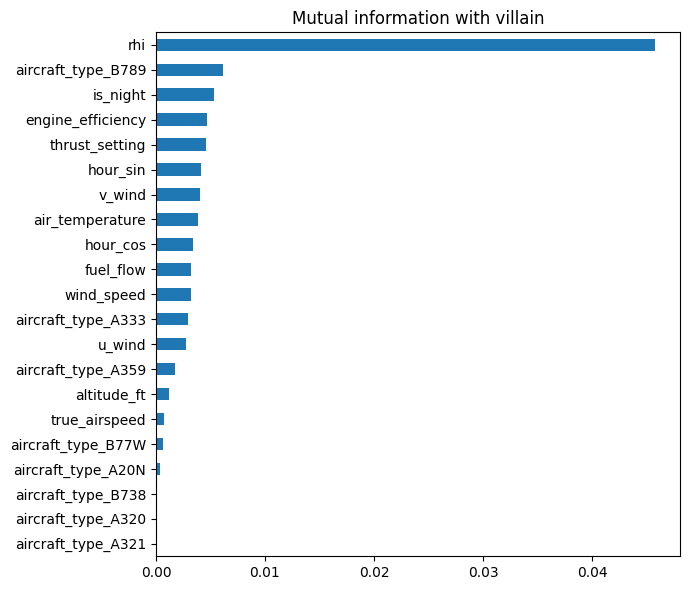

ตัดเพราะ correlation สูง: ['rh', 'rhi_lag5', 'rhi_roll10', 'temp_lag5', 'air_pressure']
RFE เลือก: ['altitude_ft', 'air_temperature', 'rhi', 'u_wind', 'hour_sin', 'hour_cos', 'is_night', 'aircraft_type_A333', 'aircraft_type_A359', 'aircraft_type_B789']


In [5]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

vt = VarianceThreshold(1e-6).fit(X_all)
kept = X_all.columns[vt.get_support()]

c = X_all[kept].corr().abs()
upper = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
drop_corr = [col for col in upper.columns if (upper[col] > 0.95).any()]
kept = [k for k in kept if k not in drop_corr]

sub = np.random.default_rng(SEED).choice(len(X_all), min(30000, len(X_all)), replace=False)
mi = pd.Series(mutual_info_classif(X_all.iloc[sub][kept], y_all[sub], random_state=SEED), index=kept).sort_values()
mi.plot.barh(figsize=(7, 6), title="Mutual information with villain"); plt.tight_layout()
plt.savefig(FIG_DIR / "mutual_info.png", dpi=150); plt.show()

rfe = RFE(LogisticRegression(max_iter=2000, class_weight="balanced"), n_features_to_select=min(10, len(kept)))
rfe.fit(StandardScaler().fit_transform(X_all.iloc[sub][kept]), y_all[sub])
SELECTED = [f for f, s in zip(kept, rfe.support_) if s]
print("ตัดเพราะ correlation สูง:", drop_corr)
print("RFE เลือก:", SELECTED)

## C. แบ่งข้อมูล + เทรน 8 โมเดล
- แบ่ง train/test **ตามเที่ยวบิน** (GroupShuffleSplit) ไม่ให้จุดของเที่ยวบินเดียวกันอยู่ทั้งสองฝั่ง ไม่งั้นผลจะดีเกินจริง
- tune ด้วย RandomizedSearchCV + GroupKFold 3 fold วัดด้วย average precision (PR-AUC) เพราะข้อมูลไม่สมดุล
- โมเดลที่ไม่มี class weight (KNN, NB, MLP) ใช้ SMOTE ใน pipeline
- SVM กับ KNN ช้ากับข้อมูลใหญ่ จึงเทรนบนตัวอย่างย่อย 20,000 แถว

In [8]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import loguniform, randint, uniform

try:
    from xgboost import XGBClassifier
    def make_boost(pos_weight):
        return XGBClassifier(n_estimators=300, eval_metric="aucpr", scale_pos_weight=pos_weight,
                             random_state=SEED, n_jobs=-1)
    BOOST_GRID = {"clf__max_depth": randint(3, 9), "clf__learning_rate": loguniform(0.02, 0.3),
                  "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.6, 0.4)}
    BOOST_NAME = "XGBoost"
except Exception:  # สำรองถ้าลง xgboost ไม่ได้
    from sklearn.ensemble import HistGradientBoostingClassifier
    def make_boost(pos_weight):
        return HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
    BOOST_GRID = {"clf__max_depth": randint(3, 9), "clf__learning_rate": loguniform(0.02, 0.3)}
    BOOST_NAME = "GradientBoosting"

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X_all, y_all, groups))
X_tr, X_te, y_tr, y_te, g_tr = X_all.iloc[tr], X_all.iloc[te], y_all[tr], y_all[te], groups[tr]
pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
print(f"train {len(tr):,}  test {len(te):,}  villain rate train {y_tr.mean():.2%} test {y_te.mean():.2%}")

ALL = list(X_all.columns)
smote = SMOTE(random_state=SEED)
MODELS = {
    "Decision Tree": (ALL, Pipeline([("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
                      {"clf__max_depth": randint(3, 15), "clf__min_samples_leaf": randint(5, 200)}, None),
    "Naive Bayes": (SELECTED, ImbPipeline([("sc", StandardScaler()), ("sm", smote), ("clf", GaussianNB())]),
                    {"clf__var_smoothing": loguniform(1e-11, 1e-5)}, None),
    "Logistic Regression": (SELECTED, Pipeline([("sc", StandardScaler()),
                            ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
                            {"clf__C": loguniform(1e-3, 1e2)}, None),
    "SVM": (SELECTED, Pipeline([("sc", StandardScaler()),
            ("clf", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
            {"clf__C": loguniform(0.1, 30), "clf__gamma": loguniform(1e-3, 1)}, 20000),
    "KNN": (SELECTED, ImbPipeline([("sc", StandardScaler()), ("sm", smote), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": randint(5, 60), "clf__weights": ["uniform", "distance"]}, 20000),
    "Random Forest": (ALL, Pipeline([("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                      n_jobs=-1, random_state=SEED))]),
                      {"clf__max_depth": randint(5, 25), "clf__min_samples_leaf": randint(1, 50),
                       "clf__max_features": ["sqrt", 0.5]}, 60000),
    BOOST_NAME: (ALL, Pipeline([("clf", make_boost(pos_weight))]), BOOST_GRID, None),
    "MLP": (SELECTED, ImbPipeline([("sc", StandardScaler()), ("sm", smote),
            ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", early_stopping=True,
                                  max_iter=300, random_state=SEED))]),
            {"clf__alpha": loguniform(1e-5, 1e-2), "clf__learning_rate_init": loguniform(1e-4, 1e-2)}, 60000),
}

train 208,744  test 54,301  villain rate train 2.13% test 2.10%


In [9]:
import time
N_ITER = 20
fitted = globals().get("fitted", {})
rng = np.random.default_rng(SEED)
for name, (feats, pipe, grid, cap) in MODELS.items():
    if name in fitted:
        continue
    t0 = time.time()
    idx = np.arange(len(X_tr))
    if cap and len(idx) > cap:
        idx = rng.choice(idx, cap, replace=False)
    search = RandomizedSearchCV(pipe, grid, n_iter=N_ITER, scoring="average_precision",
                                cv=GroupKFold(n_splits=3), random_state=SEED, n_jobs=-1)
    search.fit(X_tr.iloc[idx][feats], y_tr[idx], groups=g_tr[idx])
    fitted[name] = (feats, search.best_estimator_, search.best_params_, search.best_score_)
    print(f"{name:20s} CV PR-AUC {search.best_score_:.3f}  ({time.time() - t0:.0f}s)")

Random Forest        CV PR-AUC 0.450  (858s)
XGBoost              CV PR-AUC 0.493  (426s)
MLP                  CV PR-AUC 0.453  (1762s)


In [10]:
import joblib
joblib.dump(fitted, BASE / "fitted_checkpoint.joblib")
print("saved", list(fitted))

saved ['Decision Tree', 'Naive Bayes', 'Logistic Regression', 'SVM', 'KNN', 'Random Forest', 'XGBoost', 'MLP']


## D. ประเมินผลบน test set
- **PR-AUC (average precision):** ตัววัดหลัก เหมาะกับข้อมูลไม่สมดุล
- **Recall@top-k:** ถ้าสายการบินมีงบให้เปลี่ยนเส้นทางได้ k ช่วงบิน (k = จำนวนตัวร้ายจริง) โมเดลจับตัวร้ายได้กี่ %
- **ส่วนแบ่ง EF ที่จับได้:** ตัวร้ายที่จับได้รวมกันคิดเป็นกี่ % ของความร้อนทั้งหมด (มุม business)
- ไม่ใช้ accuracy เพราะทายว่า "ไม่ใช่ตัวร้าย" ทุกจุดก็ได้ accuracy เกิน 95% แล้ว

In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, \
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

ef_te = df["ef"].clip(lower=0).values[te]
rows, probs = [], {}
k = int(y_te.sum())
for name, (feats, model, params, cv) in fitted.items():
    p = model.predict_proba(X_te[feats])[:, 1]
    probs[name] = p
    pred = (p >= 0.5).astype(int)
    top = np.argsort(-p)[:k]
    rows.append({"model": name, "CV PR-AUC": cv, "PR-AUC": average_precision_score(y_te, p),
                 "ROC-AUC": roc_auc_score(y_te, p), "F1": f1_score(y_te, pred),
                 "Precision": precision_score(y_te, pred, zero_division=0), "Recall": recall_score(y_te, pred),
                 "Recall@top-k": y_te[top].mean() if k else np.nan,
                 "EF captured@top-k": ef_te[top].sum() / ef_te.sum() if ef_te.sum() else np.nan})
results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).round(3)
results.to_csv(FIG_DIR / "model_results.csv", index=False)
BEST = results.iloc[0]["model"]
print("โมเดลที่ดีที่สุด:", BEST)
results

โมเดลที่ดีที่สุด: XGBoost


,model,CV PR-AUC,PR-AUC,ROC-AUC,F1,Precision,Recall,Recall@top-k,EF captured@top-k
6,XGBoost,0.493,0.472,0.980,0.457,0.311,0.859,0.447,0.504
5,Random Forest,0.450,0.463,0.979,0.424,0.281,0.860,0.437,0.474
3,SVM,0.460,0.446,0.980,0.345,0.570,0.248,0.462,0.483
7,MLP,0.453,0.431,0.978,0.463,0.338,0.733,0.461,0.478
1,Naive Bayes,0.443,0.378,0.978,0.195,0.108,1.000,0.424,0.445
2,Logistic Regression,0.406,0.376,0.975,0.279,0.162,0.998,0.404,0.430
4,KNN,0.340,0.349,0.970,0.338,0.205,0.966,0.394,0.398
0,Decision Tree,0.349,0.280,0.939,0.351,0.220,0.867,0.382,0.381


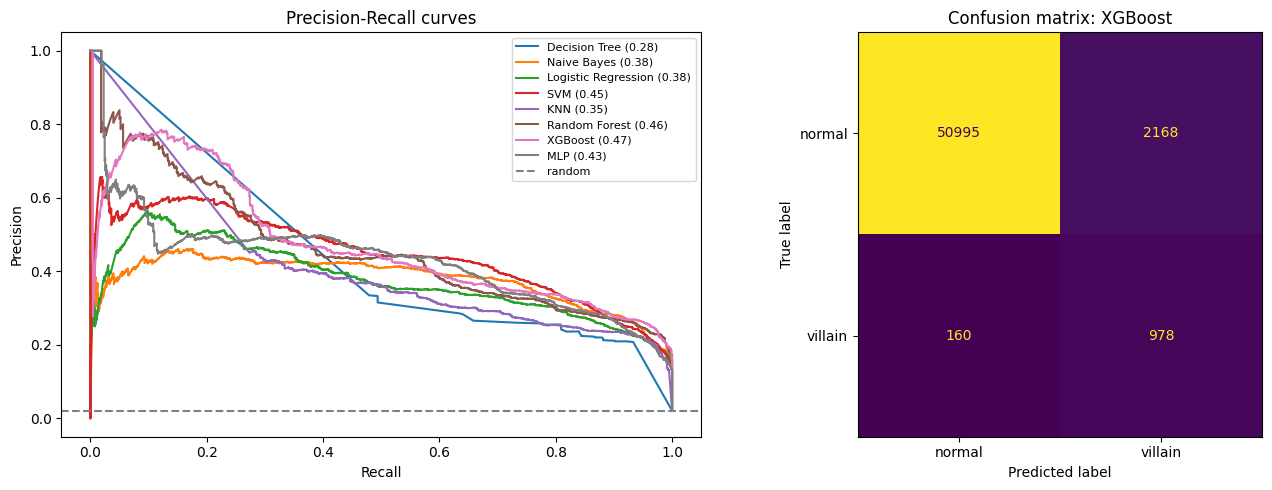

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probs.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax[0].plot(rc, pr, label=f"{name} ({average_precision_score(y_te, p):.2f})")
ax[0].axhline(y_te.mean(), ls="--", c="gray", label="random")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall curves"); ax[0].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_te, (probs[BEST] >= 0.5).astype(int)),
                       display_labels=["normal", "villain"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix: {BEST}")
plt.tight_layout(); plt.savefig(FIG_DIR / "model_comparison.png", dpi=150); plt.show()

## E. อธิบายโมเดล (L10)
1. Permutation importance ของโมเดลที่ดีที่สุด
2. SHAP บนโมเดลต้นไม้ที่ดีที่สุด: bar (ภาพรวม), beeswarm (ทิศทาง), dependence (rhi), waterfall (อธิบายตัวร้าย 1 จุด)
3. EBM: โมเดลที่ตีความได้ในตัว เทียบความแม่นกับกล่องดำ

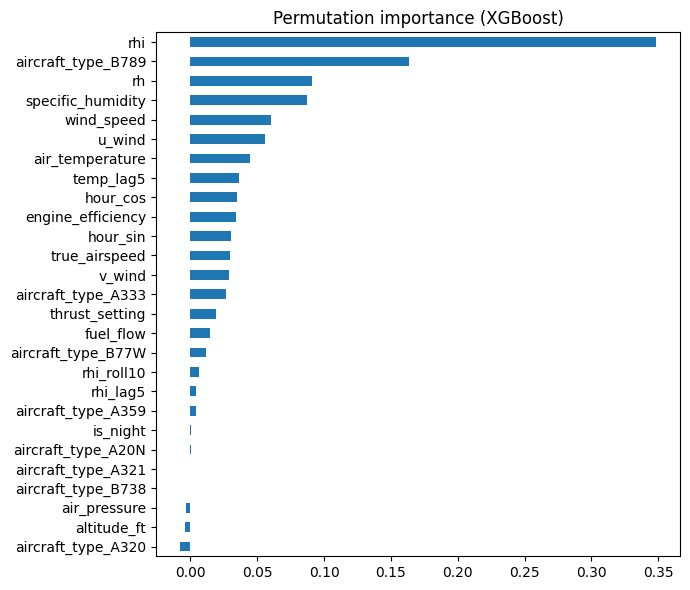

In [13]:
from sklearn.inspection import permutation_importance

feats, model, _, _ = fitted[BEST]
sub_te = np.random.default_rng(SEED).choice(len(X_te), min(10000, len(X_te)), replace=False)
pi = permutation_importance(model, X_te.iloc[sub_te][feats], y_te[sub_te], scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
pd.Series(pi.importances_mean, index=feats).sort_values().plot.barh(figsize=(7, 6),
    title=f"Permutation importance ({BEST})")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150); plt.show()

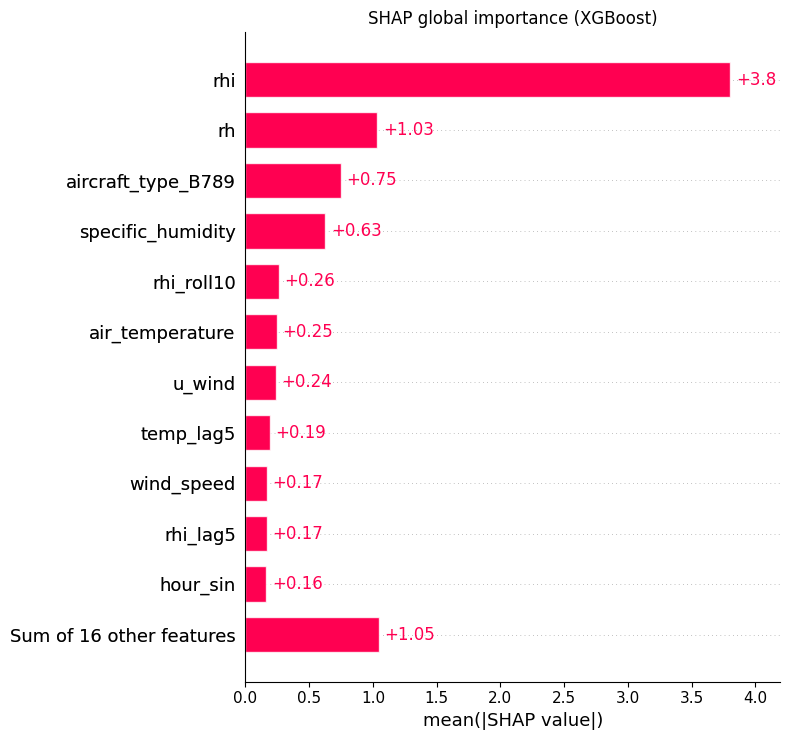

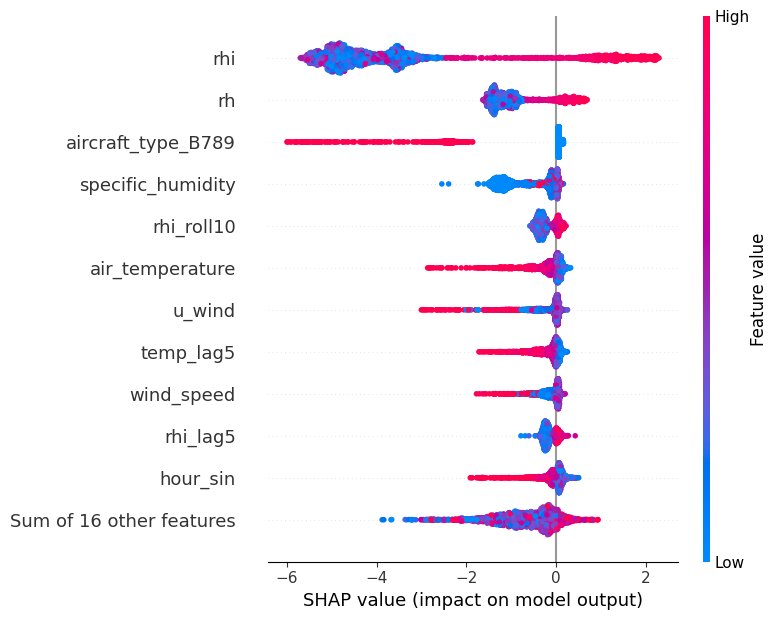

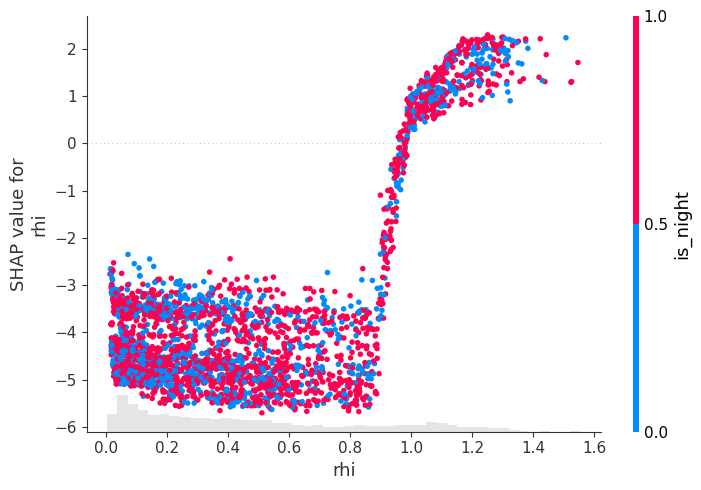

In [14]:
import shap

tree_name = BOOST_NAME if results.set_index("model").loc[BOOST_NAME, "PR-AUC"] >= \
    results.set_index("model").loc["Random Forest", "PR-AUC"] else "Random Forest"
feats, model, _, _ = fitted[tree_name]
X_shap = X_te.iloc[sub_te[:3000]][feats]
explainer = shap.TreeExplainer(model.named_steps["clf"])
sv = explainer(X_shap)
if sv.values.ndim == 3:          # random forest คืนค่าแยก 2 class เอาเฉพาะ class ตัวร้าย
    sv = sv[:, :, 1]

shap.plots.bar(sv, max_display=12, show=False); plt.title(f"SHAP global importance ({tree_name})")
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_bar.png", dpi=150); plt.show()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_beeswarm.png", dpi=150); plt.show()
shap.plots.scatter(sv[:, "rhi"], color=sv[:, "is_night"] if "is_night" in feats else None, show=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_dependence_rhi.png", dpi=150); plt.show()

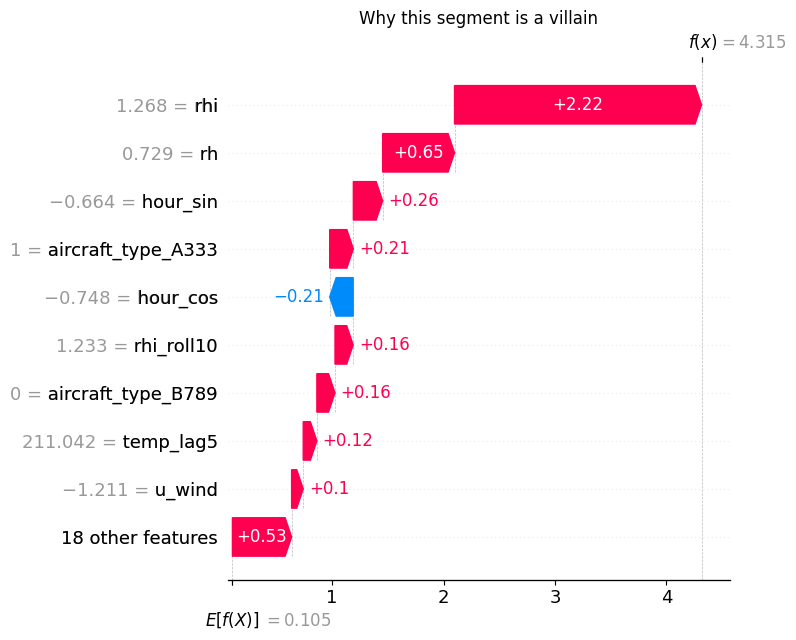

In [15]:
villain_rows = np.where(y_te[sub_te[:3000]] == 1)[0]
if len(villain_rows):
    i = villain_rows[np.argmax(model.predict_proba(X_shap.iloc[villain_rows])[:, 1])]
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title("Why this segment is a villain"); plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_waterfall.png", dpi=150); plt.show()

EBM PR-AUC 0.318 vs XGBoost 0.472


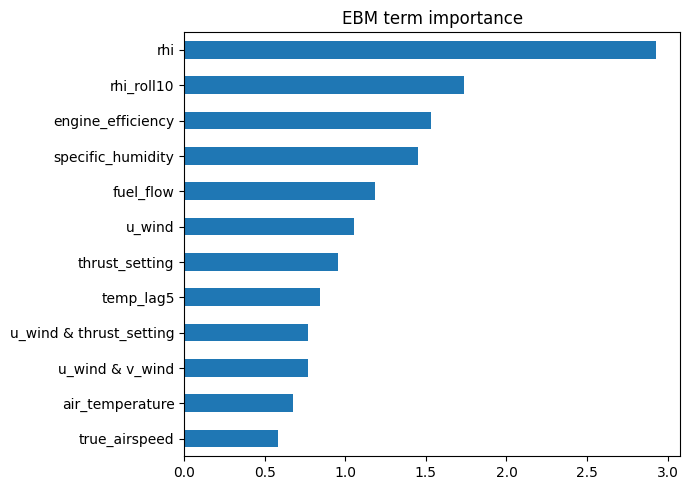

In [16]:
from interpret.glassbox import ExplainableBoostingClassifier

ebm_feats = [f for f in NUM_FEATURES if f in X_all]
idx = np.random.default_rng(SEED).choice(len(X_tr), min(60000, len(X_tr)), replace=False)
ebm = ExplainableBoostingClassifier(random_state=SEED, interactions=5)
ebm.fit(X_tr.iloc[idx][ebm_feats], y_tr[idx])
p_ebm = ebm.predict_proba(X_te[ebm_feats])[:, 1]
print(f"EBM PR-AUC {average_precision_score(y_te, p_ebm):.3f} vs {BEST} {results.iloc[0]['PR-AUC']:.3f}")

imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), title="EBM term importance"); plt.tight_layout()
plt.savefig(FIG_DIR / "ebm_importance.png", dpi=150); plt.show()

## F. PCA + KMeans: ตัวร้ายเกิดในอากาศแบบไหน (L08, L09)
ลดมิติข้อมูลอากาศของช่วงบินตัวร้ายด้วย PCA แล้วจับกลุ่มด้วย KMeans เลือกจำนวนกลุ่มจาก silhouette score

PCA explained variance: [0.349 0.202]
silhouette: {2: np.float64(0.229), 3: np.float64(0.174), 4: np.float64(0.162), 5: np.float64(0.162), 6: np.float64(0.166)} -> K = 2


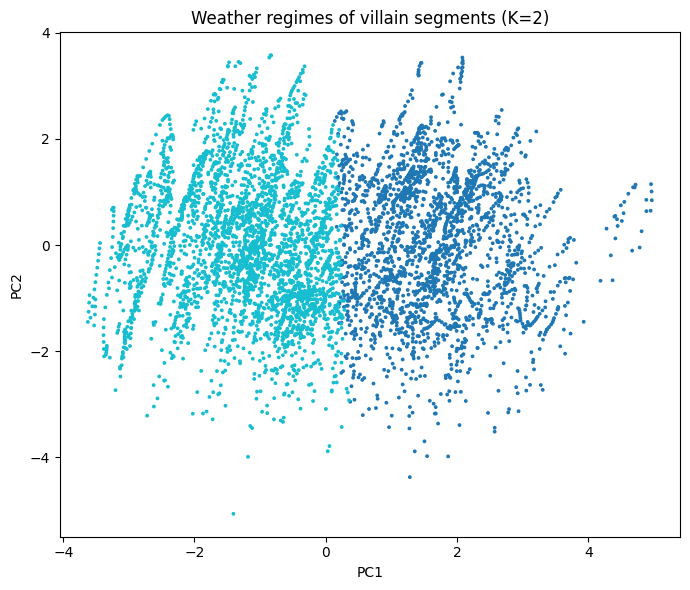

,air_temperature,rhi,rhi_roll10,specific_humidity,wind_speed,altitude_ft,hour_sin,hour_cos
cluster,,,,,,,,
0,220.539993,1.22,1.16,0.0,25.260000,31570.09,-0.03,0.15
1,211.429993,1.16,1.10,0.0,28.139999,36138.89,-0.12,0.24


In [17]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

WX = [c for c in ["air_temperature", "rhi", "rhi_roll10", "specific_humidity", "wind_speed", "altitude_ft",
                  "hour_sin", "hour_cos"] if c in df]
V = df.loc[df["villain"] == 1, WX].dropna()
V = V.sample(min(20000, len(V)), random_state=SEED)
Z = StandardScaler().fit_transform(V)
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3))

scores = {kk: silhouette_score(Z, KMeans(kk, n_init=10, random_state=SEED).fit_predict(Z),
                               sample_size=min(5000, len(Z)), random_state=SEED) for kk in range(2, 7)}
K = max(scores, key=scores.get)
labels = KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)
print("silhouette:", {kk: round(v, 3) for kk, v in scores.items()}, "-> K =", K)

plt.figure(figsize=(7, 6)); plt.scatter(P[:, 0], P[:, 1], c=labels, s=3, cmap="tab10")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"Weather regimes of villain segments (K={K})")
plt.tight_layout(); plt.savefig(FIG_DIR / "villain_clusters.png", dpi=150); plt.show()
V.assign(cluster=labels).groupby("cluster").mean().round(2)

## G. เอาโมเดลยุโรปไปทายฟ้าไทย/อาเซียน
ต้องรัน notebook 01 ด้วย `REGION = "sea"` ก่อน ถ้ายังไม่มีไฟล์ cell นี้จะข้ามไป

In [18]:
sea_path = DATA_DIR / "dataset_sea_v1.parquet"
if sea_path.exists():
    sea = add_features(pd.read_parquet(sea_path))
    Xs = pd.get_dummies(sea[NUM_FEATURES + CAT_FEATURES], columns=CAT_FEATURES, dtype=float)
    Xs = Xs.reindex(columns=X_all.columns, fill_value=0).fillna(X_all.median())
    ys = sea["villain"].astype(int).values
    print(f"SEA: {len(sea):,} ช่วงบิน, มี contrail EF {(sea['ef'] != 0).mean():.2%}, ตัวร้าย {ys.mean():.2%}")
    for name in [BEST, "Logistic Regression"]:
        feats, model, _, _ = fitted[name]
        if ys.sum():
            print(f"{name}: PR-AUC on SEA {average_precision_score(ys, model.predict_proba(Xs[feats])[:, 1]):.3f}")
else:
    print("ยังไม่มีข้อมูล SEA ข้ามส่วนนี้")

ยังไม่มีข้อมูล SEA ข้ามส่วนนี้


In [19]:
import joblib
joblib.dump({"fitted": fitted, "features": list(X_all.columns), "best": BEST}, BASE / "models.joblib")
print("saved models and figures to", BASE)

saved models and figures to /content/drive/MyDrive/Environmental-ML-Project
